# Crack Classification — RepViT (Corrected)

Binary classification: crack vs no_crack.

**Dataset:** 40,000 images — 28,000 train / 8,000 validation / 4,000 test
**Model:** `repvit_m1.dist_in1k` (ImageNet-pretrained)
**Framework:** PyTorch + timm

**Family:** CNN (mobile-efficient). Same conservative training pattern as ConvNeXt V2-Tiny and EfficientNetV2-S.

This notebook follows the same corrected pattern used for ConvNeXt V2-Tiny and EfficientNetV2-S: conservative learning rate, gradient clipping, explicit NaN/Inf checks at every stage, fresh-run checkpoint control, class-index safety via `class_to_idx` (never assumed), and a fully working Grad-CAM section.

## Expected dataset structure
```
DATA_DIR/
├── train/
│   ├── crack/
│   └── no_crack/
├── val/
│   ├── crack/
│   └── no_crack/
└── test/
    ├── crack/
    └── no_crack/
```


## 1. Setup — install and import

In [1]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "timm", "scikit-learn", "seaborn", "grad-cam", "pillow"
])
print("Python:", sys.executable)


Python: C:\Users\Students\AppData\Local\Programs\Python\Python310\python.exe


In [2]:
import os
import time
import json
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)


C:\Users\Students\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu130
timm: 1.0.29


## 2. Configuration — edit only this cell if the path differs

In [3]:
# =========================
# USER CONFIGURATION
# =========================

DATA_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset"
OUTPUT_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\Output"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 15

# Conservative LR for fine-tuning a pretrained model — same as ConvNeXt V2 / EfficientNetV2-S.
LR = 1e-4
WEIGHT_DECAY = 1e-4


NUM_CLASSES = 2
MODEL_KEY = "repvit"
TIMM_NAME = "repvit_m1.dist_in1k"
PRETRAINED = True

# Keep AMP OFF — fp16 autocast has caused NaN losses with some modern
# architectures on this setup (observed with ConvNeXt V2's GRN layer).
USE_AMP = False

# Prevent exploding gradients.
GRAD_CLIP_NORM = 1.0

PATIENCE = 5

# IMPORTANT:
# False = always start a clean experiment.
# True = explicitly resume the saved checkpoint.
RESUME_TRAINING = False

# =========================

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"DATA_DIR does not exist: {DATA_DIR}")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "logs"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)

print("Dataset exists:", os.path.exists(DATA_DIR))
print("Output directory:", OUTPUT_DIR)
print("Learning rate:", LR)
print("AMP:", USE_AMP)


Dataset exists: True
Output directory: C:\Users\Students\Desktop\Crack classification(Indhu)\Output
Learning rate: 0.0001
AMP: False


In [4]:
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: NVIDIA GeForce RTX 5070


## 3. Dataset analytics

In [5]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def count_images(folder):
    folder = Path(folder)
    return sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS)

for split in ["train", "val", "test"]:
    split_path = Path(DATA_DIR) / split
    print(f"{split}: {count_images(split_path)} images")

print("\nExpected:")
print("Train      : 28000")
print("Validation : 8000")
print("Test       : 4000")


train: 28000 images
val: 8000 images
test: 4000 images

Expected:
Train      : 28000
Validation : 8000
Test       : 4000


## 4. Data loaders

In [6]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
val_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "val"), transform=eval_transform)
test_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_transform)

print("Train classes:", train_ds.class_to_idx)
print("Val classes:", val_ds.class_to_idx)
print("Test classes:", test_ds.class_to_idx)

assert train_ds.class_to_idx == val_ds.class_to_idx
assert train_ds.class_to_idx == test_ds.class_to_idx

assert len(train_ds) == 28000
assert len(val_ds) == 8000
assert len(test_ds) == 4000

print("\nDataset sizes verified.")


Train classes: {'crack': 0, 'no_crack': 1}
Val classes: {'crack': 0, 'no_crack': 1}
Test classes: {'crack': 0, 'no_crack': 1}

Dataset sizes verified.


In [7]:
assert "crack" in train_ds.class_to_idx
assert "no_crack" in train_ds.class_to_idx

CRACK_IDX = train_ds.class_to_idx["crack"]
NO_CRACK_IDX = train_ds.class_to_idx["no_crack"]

print("Class mapping:")
print("Crack    =", CRACK_IDX)
print("No Crack =", NO_CRACK_IDX)
print("\nClass names:", train_ds.classes)


Class mapping:
Crack    = 0
No Crack = 1

Class names: ['crack', 'no_crack']


In [8]:
pin_memory = torch.cuda.is_available()

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin_memory)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 875
Validation batches: 250
Test batches: 125


## 5. Build RepViT

In [9]:
model = timm.create_model(TIMM_NAME, pretrained=PRETRAINED, num_classes=NUM_CLASSES)
model = model.to(DEVICE)

dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
with torch.no_grad():
    dummy_out = model(dummy)

if tuple(dummy_out.shape) != (2, NUM_CLASSES):
    raise RuntimeError(f"Unexpected output shape: {tuple(dummy_out.shape)}")
if not torch.isfinite(dummy_out).all():
    raise RuntimeError("Model produced NaN/Inf in the initial forward pass.")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model: {MODEL_KEY}")
print(f"Output shape: {tuple(dummy_out.shape)}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print("Initial forward pass: OK")


Model: repvit
Output shape: (2, 2)
Total parameters: 4,716,788
Trainable parameters: 4,716,788
Initial forward pass: OK


## 6. Training and evaluation functions

In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)


In [11]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


In [12]:
scaler = torch.amp.GradScaler("cuda", enabled=(USE_AMP and torch.cuda.is_available()))

print("Loss:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Scheduler:", scheduler.__class__.__name__)
print("AMP:", USE_AMP)


Loss: CrossEntropyLoss()
Optimizer: AdamW
Scheduler: CosineAnnealingLR
AMP: False


In [13]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(USE_AMP and device.type == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss detected: {loss.item()}")

        if USE_AMP and device.type == "cuda":
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
            optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite validation loss detected: {loss.item()}")

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    return running_loss / total, correct / total


@torch.no_grad()
def get_predictions(model, loader, device):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        outputs = model(images)

        if not torch.isfinite(outputs).all():
            raise RuntimeError("Model produced NaN/Inf during evaluation.")

        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

    return np.array(all_labels), np.array(all_preds), np.concatenate(all_probs, axis=0)


## 7. Train RepViT

In [14]:
resume_path = os.path.join(OUTPUT_DIR, "checkpoints", f"{MODEL_KEY}_resume.pt")
best_path = os.path.join(OUTPUT_DIR, "checkpoints", f"{MODEL_KEY}_best.pt")
csv_log_path = os.path.join(OUTPUT_DIR, "logs", f"{MODEL_KEY}_epoch_log.csv")
history_path = os.path.join(OUTPUT_DIR, "logs", f"{MODEL_KEY}_history.json")

if RESUME_TRAINING and os.path.exists(resume_path):
    print("=" * 70)
    print("RESUMING EXISTING TRAINING")
    print("=" * 70)

    ckpt = torch.load(resume_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scheduler.load_state_dict(ckpt["scheduler_state"])
    start_epoch = ckpt["epoch"] + 1
    history = ckpt["history"]
    best_val_acc = ckpt["best_val_acc"]
    best_state = ckpt["best_state"]
    epochs_no_improve = ckpt["epochs_no_improve"]
    if scaler is not None and "scaler_state" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state"])
    print(f"Resuming at epoch {start_epoch + 1}/{EPOCHS}. Best validation accuracy: {best_val_acc*100:.2f}%")
else:
    print("=" * 70)
    print("STARTING A NEW TRAINING RUN")
    print("=" * 70)

    start_epoch = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_acc = -1.0
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0

    pd.DataFrame(columns=["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "learning_rate"]).to_csv(csv_log_path, index=False)

start_time = time.time()
stopped_early = False

for epoch in range(start_epoch, EPOCHS):
    current_lr = optimizer.param_groups[0]["lr"]

    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, DEVICE)
    val_loss, val_acc = evaluate(model, val_loader, criterion, DEVICE)
    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    marker = ""
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        marker = "\n  -> Best model saved."
    else:
        epochs_no_improve += 1

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}% | LR: {current_lr:.5g}{marker}")

    pd.DataFrame([{
        "epoch": epoch + 1, "train_loss": tr_loss, "train_acc": tr_acc,
        "val_loss": val_loss, "val_acc": val_acc, "learning_rate": current_lr
    }]).to_csv(csv_log_path, mode="a", header=False, index=False)

    checkpoint_data = {
        "epoch": epoch, "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
        "history": history, "best_val_acc": best_val_acc,
        "best_state": best_state, "epochs_no_improve": epochs_no_improve,
        "config": {
            "IMG_SIZE": IMG_SIZE, "BATCH_SIZE": BATCH_SIZE, "EPOCHS": EPOCHS, "LR": LR,
            "WEIGHT_DECAY": WEIGHT_DECAY, "MODEL_KEY": MODEL_KEY, "TIMM_NAME": TIMM_NAME,
            "NUM_CLASSES": NUM_CLASSES, "CRACK_IDX": CRACK_IDX, "NO_CRACK_IDX": NO_CRACK_IDX,
            "USE_AMP": USE_AMP, "GRAD_CLIP_NORM": GRAD_CLIP_NORM,
        }
    }
    if scaler is not None:
        checkpoint_data["scaler_state"] = scaler.state_dict()
    torch.save(checkpoint_data, resume_path)

    if epochs_no_improve >= PATIENCE:
        print(f"\nEARLY STOPPING — no improvement for {PATIENCE} epochs.")
        stopped_early = True
        break

training_time = time.time() - start_time

if best_state is None:
    raise RuntimeError("No valid best model state was produced.")

model.load_state_dict(best_state)
torch.save(best_state, best_path)

with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

status = "Stopped early" if stopped_early else "Completed all epochs"
print(f"\n{'='*70}")
print("TRAINING FINISHED")
print(f"{'='*70}")
print("Status:", status)
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")
print(f"Training time: {training_time/60:.2f} minutes")
print("Best model:", best_path)


STARTING A NEW TRAINING RUN
Epoch 01/15 | Train Loss: 0.1279 | Train Acc: 95.69% | Val Loss: 0.0695 | Val Acc: 97.54% | LR: 0.0001
  -> Best model saved.
Epoch 02/15 | Train Loss: 0.0773 | Train Acc: 97.42% | Val Loss: 0.0589 | Val Acc: 98.06% | LR: 9.8907e-05
  -> Best model saved.
Epoch 03/15 | Train Loss: 0.0633 | Train Acc: 97.92% | Val Loss: 0.1022 | Val Acc: 97.10% | LR: 9.5677e-05
Epoch 04/15 | Train Loss: 0.0579 | Train Acc: 98.18% | Val Loss: 0.1110 | Val Acc: 98.15% | LR: 9.0451e-05
  -> Best model saved.
Epoch 05/15 | Train Loss: 0.0492 | Train Acc: 98.51% | Val Loss: 0.0753 | Val Acc: 97.97% | LR: 8.3457e-05
Epoch 06/15 | Train Loss: 0.0412 | Train Acc: 98.62% | Val Loss: 0.0641 | Val Acc: 98.19% | LR: 7.5e-05
  -> Best model saved.
Epoch 07/15 | Train Loss: 0.0333 | Train Acc: 98.95% | Val Loss: 0.0748 | Val Acc: 98.08% | LR: 6.5451e-05
Epoch 08/15 | Train Loss: 0.0300 | Train Acc: 99.07% | Val Loss: 0.0755 | Val Acc: 98.05% | LR: 5.5226e-05
Epoch 09/15 | Train Loss: 0.025

## 8. Training curves

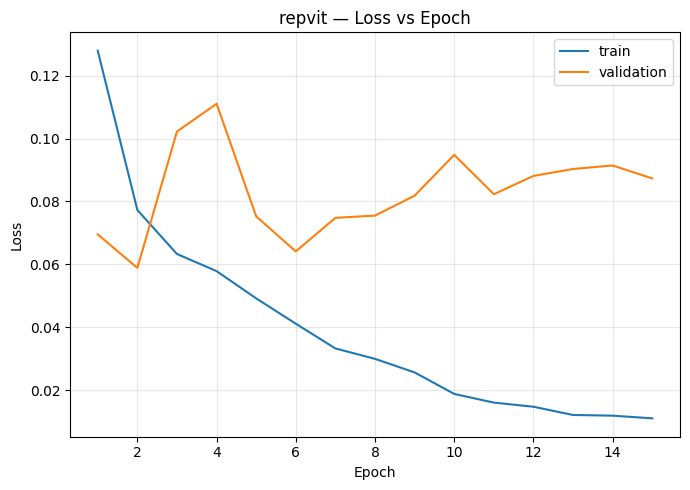

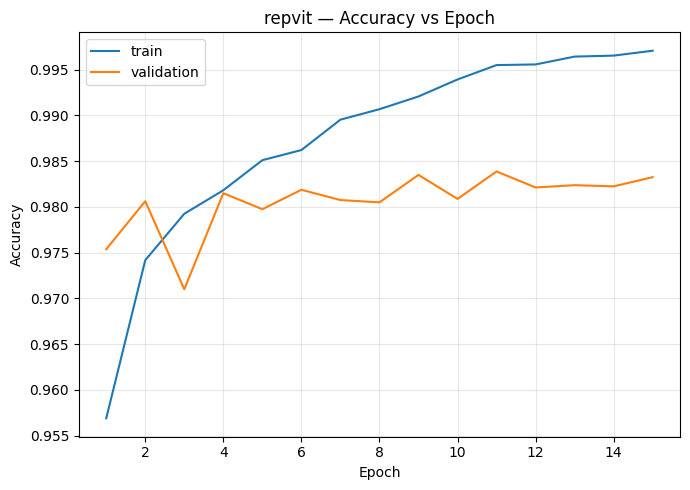

In [15]:
epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(7, 5))
plt.plot(epochs_ran, history["train_loss"], label="train")
plt.plot(epochs_ran, history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title(f"{MODEL_KEY} — Loss vs Epoch")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_loss_curve.png"), dpi=150)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(epochs_ran, history["train_acc"], label="train")
plt.plot(epochs_ran, history["val_acc"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.title(f"{MODEL_KEY} — Accuracy vs Epoch")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_accuracy_curve.png"), dpi=150)
plt.show()


## 9. Final evaluation on the test set

In [16]:
test_labels, test_preds, probs = get_predictions(model, test_loader, DEVICE)

accuracy = accuracy_score(test_labels, test_preds)
precision = precision_score(test_labels, test_preds, pos_label=CRACK_IDX, zero_division=0)
recall = recall_score(test_labels, test_preds, pos_label=CRACK_IDX, zero_division=0)
f1 = f1_score(test_labels, test_preds, pos_label=CRACK_IDX, zero_division=0)

# Probability belonging to CRACK
crack_probs = probs[:, CRACK_IDX]

# Canonical encoding for AUC/Brier: crack = 1, no_crack = 0
binary_labels = (test_labels == CRACK_IDX).astype(int)

roc_auc = roc_auc_score(binary_labels, crack_probs)
brier = brier_score_loss(binary_labels, crack_probs)

print("========== TEST RESULTS ==========")
print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision*100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall*100:.2f}%)")
print(f"F1 Score : {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"Brier    : {brier:.4f}")

result_row = {
    "Model": MODEL_KEY, "Accuracy": round(accuracy, 4), "Precision (crack)": round(precision, 4),
    "Recall (crack)": round(recall, 4), "F1-Score (crack)": round(f1, 4), "ROC-AUC": round(roc_auc, 4),
    "Brier Score": round(brier, 4), "Training Time (s)": round(training_time, 1),
    "Params (M)": round(total_params / 1e6, 2),
}
results_df = pd.DataFrame([result_row]).set_index("Model")
metrics_path = os.path.join(OUTPUT_DIR, f"{MODEL_KEY}_final_metrics.csv")
results_df.to_csv(metrics_path)
print()
print(results_df)


========== TEST RESULTS ==========
Accuracy : 0.9852 (98.52%)
Precision: 0.9904 (99.04%)
Recall   : 0.9800 (98.00%)
F1 Score : 0.9852 (98.52%)
ROC-AUC  : 0.9960
Brier    : 0.0129

        Accuracy  Precision (crack)  Recall (crack)  F1-Score (crack)  \
Model                                                                   
repvit    0.9852             0.9904            0.98            0.9852   

        ROC-AUC  Brier Score  Training Time (s)  Params (M)  
Model                                                        
repvit    0.996       0.0129             2468.2        4.72  


In [17]:
print(classification_report(
    test_labels, test_preds,
    labels=[NO_CRACK_IDX, CRACK_IDX],
    target_names=["No Crack", "Crack"],
    zero_division=0
))


              precision    recall  f1-score   support

    No Crack       0.98      0.99      0.99      2000
       Crack       0.99      0.98      0.99      2000

    accuracy                           0.99      4000
   macro avg       0.99      0.99      0.99      4000
weighted avg       0.99      0.99      0.99      4000



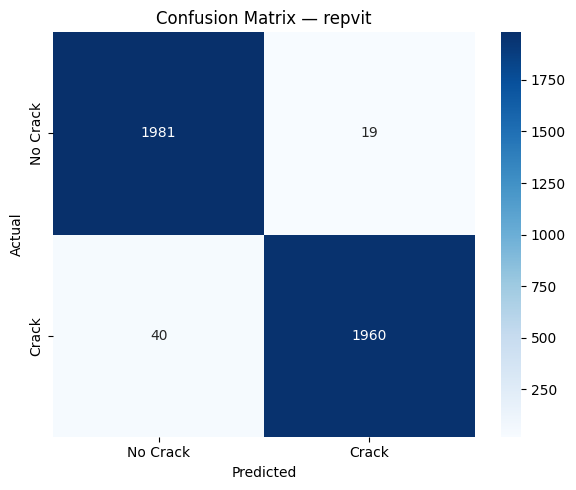

True Negative : 1981
False Positive: 19
False Negative: 40
True Positive : 1960
Total errors  : 59


In [18]:
cm = confusion_matrix(test_labels, test_preds, labels=[NO_CRACK_IDX, CRACK_IDX])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Crack", "Crack"], yticklabels=["No Crack", "Crack"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {MODEL_KEY}")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_confusion_matrix.png"), dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)
print("Total errors  :", fp + fn)


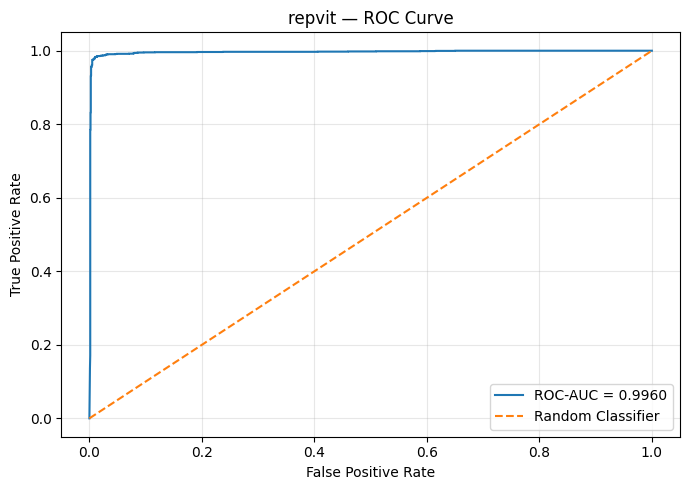

In [19]:
fpr, tpr, thresholds = roc_curve(binary_labels, crack_probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title(f"{MODEL_KEY} — ROC Curve")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_roc_curve.png"), dpi=150)
plt.show()

roc_df = pd.DataFrame({"False Positive Rate": fpr, "True Positive Rate": tpr, "Threshold": thresholds})
roc_df.to_csv(os.path.join(OUTPUT_DIR, f"{MODEL_KEY}_roc_curve.csv"), index=False)


## 10. Calibration check

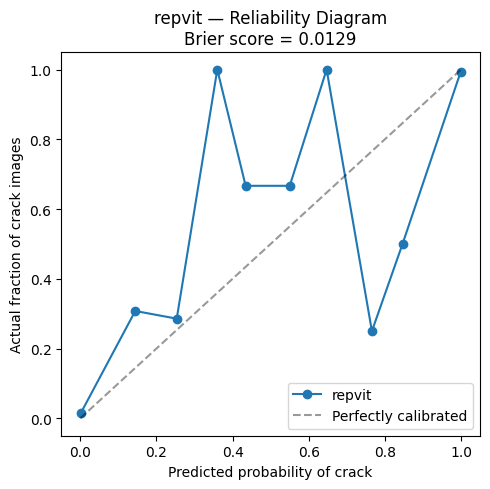

Brier score: 0.0129


In [20]:
prob_true, prob_pred = calibration_curve(binary_labels, crack_probs, n_bins=10, strategy="uniform")

plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label=MODEL_KEY)
plt.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Perfectly calibrated")
plt.xlabel("Predicted probability of crack")
plt.ylabel("Actual fraction of crack images")
plt.title(f"{MODEL_KEY} — Reliability Diagram\nBrier score = {brier:.4f}")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_calibration.png"), dpi=150)
plt.show()

print(f"Brier score: {brier:.4f}")


## 11. Failure case analysis

In [21]:
misclassified_indices = np.where(test_labels != test_preds)[0]
print("Total misclassified images:", len(misclassified_indices))
print(f"Error rate: {len(misclassified_indices) / len(test_ds) * 100:.2f}%")

false_positive_indices = np.where((test_labels == NO_CRACK_IDX) & (test_preds == CRACK_IDX))[0]
false_negative_indices = np.where((test_labels == CRACK_IDX) & (test_preds == NO_CRACK_IDX))[0]

print("False Positive images:", len(false_positive_indices))
print("False Negative images:", len(false_negative_indices))


Total misclassified images: 59
Error rate: 1.47%
False Positive images: 19
False Negative images: 40


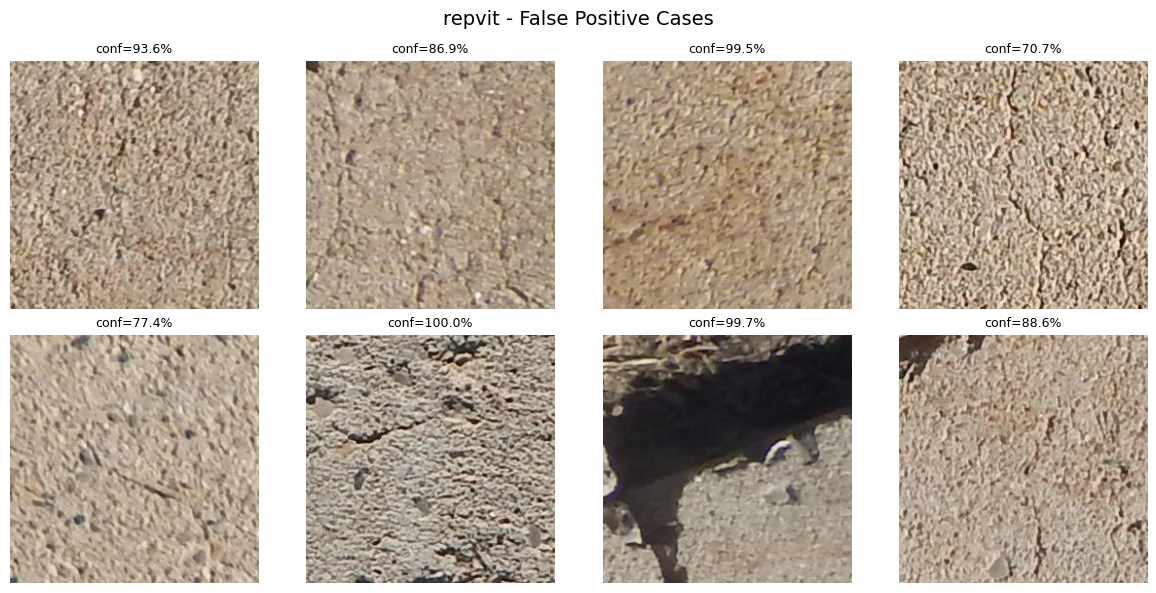

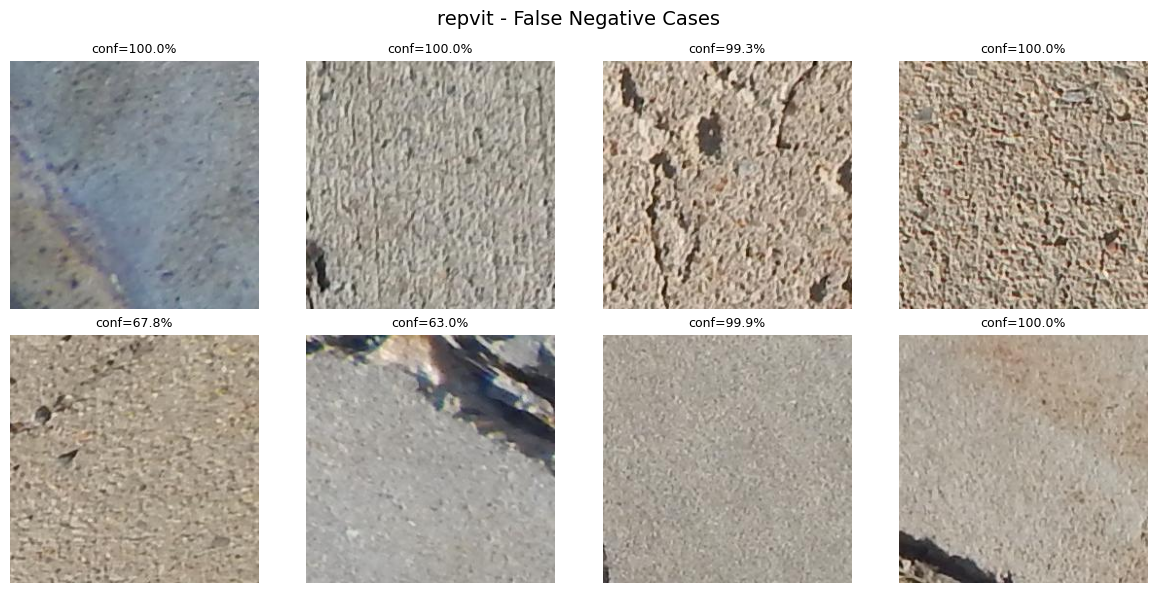

In [22]:
def show_failure_grid(indices, title, probs_col, max_images=8):
    n = min(len(indices), max_images)
    if n == 0:
        print("No examples to show for:", title)
        return
    cols = 4
    rows = (n + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3 * rows))
    for plot_idx, data_idx in enumerate(indices[:n]):
        image_path = test_ds.samples[data_idx][0]
        image = Image.open(image_path).convert("RGB")
        confidence_value = probs[data_idx, probs_col] * 100
        plt.subplot(rows, cols, plot_idx + 1)
        plt.imshow(image)
        plt.axis("off")
        plt.title(f"conf={confidence_value:.1f}%", fontsize=9)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    safe_name = title.lower().replace(" ", "_").replace("(", "").replace(")", "")
    plt.savefig(os.path.join(OUTPUT_DIR, "figures", f"{MODEL_KEY}_{safe_name}.png"), dpi=150)
    plt.show()

show_failure_grid(false_positive_indices, f"{MODEL_KEY} - False Positive Cases", probs_col=CRACK_IDX)
show_failure_grid(false_negative_indices, f"{MODEL_KEY} - False Negative Cases", probs_col=NO_CRACK_IDX)


**Write down what you notice** — do false negatives tend to be thin/hairline cracks? Do false positives share something visually (shadows, stains, texture)? Are the wrong predictions high-confidence (concerning) or low-confidence (model was unsure)?


## 12. Grad-CAM explainability — RepViT

Dataset class mapping: {'crack': 0, 'no_crack': 1}
Crack example:
Actual: crack | Predicted: crack | Confidence: 100.00%


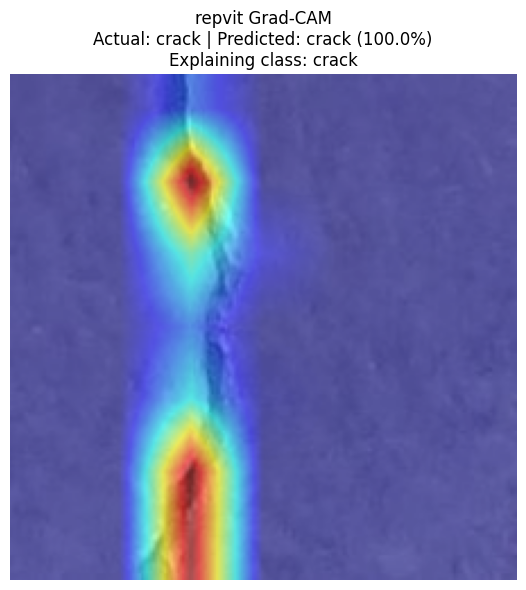


No-crack example:
Actual: no_crack | Predicted: no_crack | Confidence: 100.00%


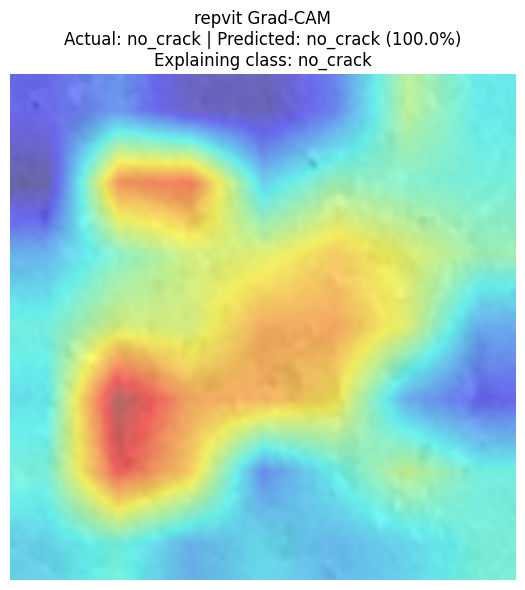


A false-negative case (missed real crack):
Actual: crack | Predicted: no_crack | Confidence: 100.00%


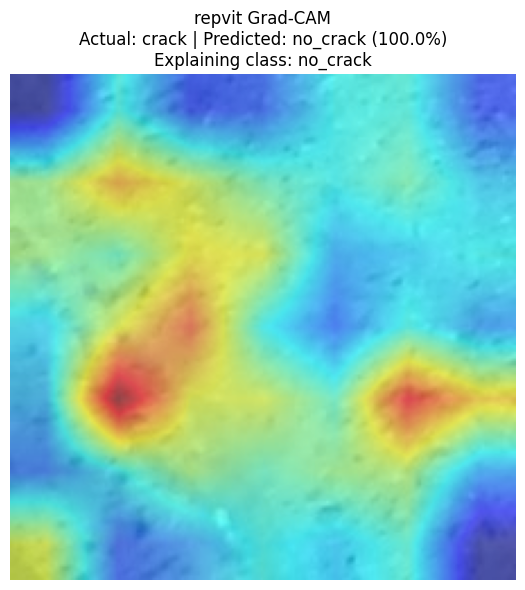

In [23]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("Dataset class mapping:", test_ds.class_to_idx)

def find_last_conv_layer(model):
    """Auto-detect the last Conv2d layer rather than hardcoding an attribute
    path — robust across architectures without needing to know internal naming."""
    last_conv = None
    for module in model.modules():
        if isinstance(module, torch.nn.Conv2d):
            last_conv = module
    if last_conv is None:
        raise RuntimeError("No Conv2d layer found in this model — Grad-CAM needs a conv target.")
    return last_conv

target_layers = [find_last_conv_layer(model)]
gradcam = GradCAM(model=model, target_layers=target_layers)


def show_gradcam(data_idx, gradcam, target_class=None):
    model.eval()
    image_path = test_ds.samples[data_idx][0]
    actual_class = os.path.basename(os.path.dirname(image_path))

    img = Image.open(image_path).convert("RGB")
    input_tensor = eval_transform(img).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.softmax(output, dim=1)
        predicted_class = output.argmax(dim=1).item()

    class_names = test_ds.classes
    predicted_name = class_names[predicted_class]
    confidence = probabilities[0, predicted_class].item() * 100

    print(f"Actual: {actual_class} | Predicted: {predicted_name} | Confidence: {confidence:.2f}%")

    if target_class is None:
        target_class = predicted_class
    target_name = class_names[target_class]

    targets = [ClassifierOutputTarget(target_class)]
    grayscale_cam = gradcam(input_tensor=input_tensor, targets=targets)[0]

    rgb_img = np.asarray(img.resize((IMG_SIZE, IMG_SIZE))).astype(np.float32) / 255.0
    visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

    plt.figure(figsize=(6, 6))
    plt.imshow(visualization)
    plt.title(f"{MODEL_KEY} Grad-CAM\nActual: {actual_class} | Predicted: {predicted_name} ({confidence:.1f}%)\nExplaining class: {target_name}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


crack_path_idx = next(i for i, (p, l) in enumerate(test_ds.samples) if l == CRACK_IDX)
no_crack_path_idx = next(i for i, (p, l) in enumerate(test_ds.samples) if l == NO_CRACK_IDX)

print("Crack example:")
show_gradcam(data_idx=crack_path_idx, gradcam=gradcam)

print("\nNo-crack example:")
show_gradcam(data_idx=no_crack_path_idx, gradcam=gradcam)

if len(false_negative_indices) > 0:
    print("\nA false-negative case (missed real crack):")
    show_gradcam(data_idx=false_negative_indices[0], gradcam=gradcam)
else:
    print("No false-negative cases found.")


## 13. Saved files

- Best checkpoint: `{OUTPUT_DIR}\checkpoints\repvit_best.pt`
- Training history: `{OUTPUT_DIR}\logs\repvit_history.json`
- Final metrics: `{OUTPUT_DIR}\repvit_final_metrics.csv`
- Epoch log: `{OUTPUT_DIR}\logs\repvit_epoch_log.csv`
- Figures: `{OUTPUT_DIR}\figures\repvit_*.png`

**Before trusting these results:** confirm training loss stayed finite throughout, validation accuracy rose clearly above 50% (random-guessing baseline for this balanced dataset), both classes were actually predicted at test time, and the best validation checkpoint (not the last epoch) was used for evaluation. Only then use these Accuracy/Precision/Recall/F1/ROC-AUC/calibration/failure-analysis/Grad-CAM results in your final comparison with the other models.
